# Tugas Data Visualization: Analisis Penjualan Jersey Futsal
**Nama:** (isi nama) &nbsp;|&nbsp; **NIM:** 2418066 &nbsp;|&nbsp; **Pertemuan ke-6**

**Tujuan:** memvisualisasikan data penjualan jersey (jenis, ukuran, jumlah, harga, waktu) untuk menemukan pola penjualan.
**Dataset:** 100 transaksi (1 Sep - 7 Okt 2026), tertanam langsung di notebook dan juga tersedia sebagai `data_jersey_bersih_enrichment_100.csv`.

## 1. Import Library & Load Data

In [1]:
import io
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (9, 5)

# Data sudah tertanam di notebook, jadi TIDAK perlu upload file apa pun
DATA = '''ID,Tanggal_Transaksi,Jenis_Jersey,Ukuran_Jersey,Jumlah_Terjual,Harga,Total_Penjualan,Total_Dikoreksi,Valid_Tanggal,Valid_Jenis,Valid_Ukuran,Valid_Jumlah,Valid_Harga,Masalah,Hari,Minggu_Ke,Kategori_Jumlah,Kelompok_Ukuran,Tipe_Jersey
1,2026-09-01,Jersey Polos,M,10,85000,850000,False,True,True,True,True,True,,Selasa,36,Besar,Kecil,Standar
2,2026-09-01,Jersey Polos,M,5,85000,425000,False,True,True,True,True,True,,Selasa,36,Sedang,Kecil,Standar
3,2026-09-01,Jersey Printing,L,12,110000,1320000,False,True,True,True,True,True,,Selasa,36,Besar,Besar,Custom
4,2026-09-02,Jersey Sublimasi,XL,6,135000,810000,False,True,True,True,True,True,,Rabu,36,Sedang,Besar,Custom
5,2026-09-02,Jersey Full Print,L,4,150000,600000,False,True,True,True,True,True,,Rabu,36,Sedang,Besar,Custom
6,2026-09-02,Jersey Kiper,S,2,125000,250000,False,True,True,True,True,True,,Rabu,36,Kecil,Kecil,Khusus
7,2026-09-02,Jersey Polos,M,8,85000,680000,False,True,True,True,True,True,,Rabu,36,Besar,Kecil,Standar
8,2026-09-03,Jersey Printing,XXL,3,110000,330000,False,True,True,True,True,True,,Kamis,36,Kecil,Besar,Custom
9,2026-09-03,Jersey Sublimasi,L,7,135000,945000,False,True,True,True,True,True,,Kamis,36,Sedang,Besar,Custom
10,2026-09-03,Jersey Polos,M,6,85000,510000,False,True,True,True,True,True,,Kamis,36,Sedang,Kecil,Standar
11,2026-09-04,Jersey Full Print,L,5,150000,750000,False,True,True,True,True,True,,Jumat,36,Sedang,Besar,Custom
12,2026-09-04,Jersey Polos,M,5,85000,425000,False,True,True,True,True,True,,Jumat,36,Sedang,Kecil,Standar
13,2026-09-04,Jersey Kiper,XL,3,125000,375000,True,True,True,True,True,True,,Jumat,36,Kecil,Besar,Khusus
14,2026-09-05,Jersey Printing,XL,7,110000,770000,False,True,True,True,True,True,,Sabtu,36,Sedang,Besar,Custom
15,2026-09-05,Jersey Full Print,M,9,150000,1350000,False,True,True,True,True,True,,Sabtu,36,Besar,Kecil,Custom
16,2026-09-05,Jersey Sublimasi,L,5,135000,675000,False,True,True,True,True,True,,Sabtu,36,Sedang,Besar,Custom
17,2026-09-06,Jersey Polos,S,4,85000,340000,False,True,True,True,True,True,,Minggu,36,Sedang,Kecil,Standar
18,2026-09-07,Jersey Sublimasi,XXL,2,135000,270000,False,True,True,True,True,True,,Senin,37,Kecil,Besar,Custom
19,2026-09-07,Jersey Polos,M,6,85000,510000,False,True,True,True,True,True,,Senin,37,Sedang,Kecil,Standar
20,2026-09-07,Jersey Full Print,XL,5,150000,750000,True,True,True,True,True,True,,Senin,37,Sedang,Besar,Custom
21,2026-09-08,Jersey Polos,Tidak Diketahui,5,85000,425000,False,True,True,True,True,True,,Selasa,37,Sedang,Tidak Diketahui,Standar
22,2026-09-09,Jersey Sublimasi,L,3,135000,405000,False,True,True,True,True,True,,Rabu,37,Kecil,Besar,Custom
23,2026-09-09,Jersey Polos,L,5,85000,425000,False,True,True,True,True,True,,Rabu,37,Sedang,Besar,Standar
24,2026-09-10,Jersey Kiper,M,6,125000,750000,False,True,True,True,True,True,,Kamis,37,Sedang,Kecil,Khusus
25,2026-09-11,Jersey Full Print,L,4,150000,600000,False,True,True,True,True,True,,Jumat,37,Sedang,Besar,Custom
26,2026-09-11,Jersey Sublimasi,S,7,135000,945000,False,True,True,True,True,True,,Jumat,37,Sedang,Kecil,Custom
27,2026-09-11,Jersey Polos,XXL,8,85000,680000,False,True,True,True,True,True,,Jumat,37,Besar,Besar,Standar
28,2026-09-12,Jersey Full Print,L,5,150000,750000,False,True,True,True,True,True,,Sabtu,37,Sedang,Besar,Custom
29,2026-09-12,Jersey Printing,XXL,7,110000,770000,False,True,True,True,True,True,,Sabtu,37,Sedang,Besar,Custom
30,2026-09-12,Jersey Full Print,M,3,150000,450000,False,True,True,True,True,True,,Sabtu,37,Kecil,Kecil,Custom
31,2026-09-12,Jersey Sublimasi,L,9,135000,1215000,False,True,True,True,True,True,,Sabtu,37,Besar,Besar,Custom
32,2026-09-13,Jersey Kiper,M,10,125000,1250000,False,True,True,True,True,True,,Minggu,37,Besar,Kecil,Khusus
33,2026-09-13,Jersey Full Print,XL,2,150000,300000,False,True,True,True,True,True,,Minggu,37,Kecil,Besar,Custom
34,2026-09-14,Jersey Sublimasi,L,2,135000,270000,False,True,True,True,True,True,,Senin,38,Kecil,Besar,Custom
35,2026-09-14,Jersey Kiper,XL,10,125000,1250000,False,True,True,True,True,True,,Senin,38,Besar,Besar,Khusus
36,2026-09-14,Jersey Printing,M,5,110000,550000,False,True,True,True,True,True,,Senin,38,Sedang,Kecil,Custom
37,2026-09-15,Jersey Polos,M,3,85000,255000,False,True,True,True,True,True,,Selasa,38,Kecil,Kecil,Standar
38,2026-09-15,Jersey Kiper,M,9,125000,1125000,False,True,True,True,True,True,,Selasa,38,Besar,Kecil,Khusus
39,2026-09-15,Jersey Kiper,M,9,125000,1125000,False,True,True,True,True,True,,Selasa,38,Besar,Kecil,Khusus
40,2026-09-15,Jersey Full Print,M,3,150000,450000,False,True,True,True,True,True,,Selasa,38,Kecil,Kecil,Custom
41,2026-09-16,Jersey Kiper,L,2,125000,250000,False,True,True,True,True,True,,Rabu,38,Kecil,Besar,Khusus
42,2026-09-16,Jersey Polos,XL,7,85000,595000,False,True,True,True,True,True,,Rabu,38,Sedang,Besar,Standar
43,2026-09-17,Jersey Full Print,M,6,150000,900000,False,True,True,True,True,True,,Kamis,38,Sedang,Kecil,Custom
44,2026-09-17,Jersey Polos,L,7,85000,595000,False,True,True,True,True,True,,Kamis,38,Sedang,Besar,Standar
45,2026-09-17,Jersey Sublimasi,M,8,135000,1080000,False,True,True,True,True,True,,Kamis,38,Besar,Kecil,Custom
46,2026-09-18,Jersey Kiper,M,6,125000,750000,False,True,True,True,True,True,,Jumat,38,Sedang,Kecil,Khusus
47,2026-09-18,Jersey Printing,L,5,110000,550000,False,True,True,True,True,True,,Jumat,38,Sedang,Besar,Custom
48,2026-09-18,Jersey Printing,M,9,110000,990000,False,True,True,True,True,True,,Jumat,38,Besar,Kecil,Custom
49,2026-09-18,Jersey Printing,L,3,110000,330000,False,True,True,True,True,True,,Jumat,38,Kecil,Besar,Custom
50,2026-09-19,Jersey Kiper,M,8,125000,1000000,False,True,True,True,True,True,,Sabtu,38,Besar,Kecil,Khusus
51,2026-09-19,Jersey Kiper,M,9,125000,1125000,False,True,True,True,True,True,,Sabtu,38,Besar,Kecil,Khusus
52,2026-09-19,Jersey Polos,L,1,85000,85000,False,True,True,True,True,True,,Sabtu,38,Kecil,Besar,Standar
53,2026-09-19,Jersey Kiper,M,2,125000,250000,False,True,True,True,True,True,,Sabtu,38,Kecil,Kecil,Khusus
54,2026-09-20,Jersey Sublimasi,L,7,135000,945000,False,True,True,True,True,True,,Minggu,38,Sedang,Besar,Custom
55,2026-09-20,Jersey Sublimasi,M,3,135000,405000,False,True,True,True,True,True,,Minggu,38,Kecil,Kecil,Custom
56,2026-09-21,Jersey Printing,L,2,110000,220000,False,True,True,True,True,True,,Senin,39,Kecil,Besar,Custom
57,2026-09-21,Jersey Full Print,XXL,7,150000,1050000,False,True,True,True,True,True,,Senin,39,Sedang,Besar,Custom
58,2026-09-21,Jersey Printing,XXL,8,110000,880000,False,True,True,True,True,True,,Senin,39,Besar,Besar,Custom
59,2026-09-21,Jersey Kiper,M,3,125000,375000,False,True,True,True,True,True,,Senin,39,Kecil,Kecil,Khusus
60,2026-09-22,Jersey Polos,XXL,5,85000,425000,False,True,True,True,True,True,,Selasa,39,Sedang,Besar,Standar
61,2026-09-22,Jersey Polos,M,6,85000,510000,False,True,True,True,True,True,,Selasa,39,Sedang,Kecil,Standar
62,2026-09-22,Jersey Polos,S,8,85000,680000,False,True,True,True,True,True,,Selasa,39,Besar,Kecil,Standar
63,2026-09-23,Jersey Sublimasi,XL,6,135000,810000,False,True,True,True,True,True,,Rabu,39,Sedang,Besar,Custom
64,2026-09-23,Jersey Kiper,L,4,125000,500000,False,True,True,True,True,True,,Rabu,39,Sedang,Besar,Khusus
65,2026-09-23,Jersey Polos,M,4,85000,340000,False,True,True,True,True,True,,Rabu,39,Sedang,Kecil,Standar
66,2026-09-24,Jersey Polos,L,6,85000,510000,False,True,True,True,True,True,,Kamis,39,Sedang,Besar,Standar
67,2026-09-24,Jersey Polos,XXL,6,85000,510000,False,True,True,True,True,True,,Kamis,39,Sedang,Besar,Standar
68,2026-09-24,Jersey Printing,M,1,110000,110000,False,True,True,True,True,True,,Kamis,39,Kecil,Kecil,Custom
69,2026-09-24,Jersey Full Print,M,8,150000,1200000,False,True,True,True,True,True,,Kamis,39,Besar,Kecil,Custom
70,2026-09-25,Jersey Sublimasi,M,10,135000,1350000,False,True,True,True,True,True,,Jumat,39,Besar,Kecil,Custom
71,2026-09-25,Jersey Sublimasi,M,3,135000,405000,False,True,True,True,True,True,,Jumat,39,Kecil,Kecil,Custom
72,2026-09-26,Jersey Printing,M,5,110000,550000,False,True,True,True,True,True,,Sabtu,39,Sedang,Kecil,Custom
73,2026-09-26,Jersey Polos,S,9,85000,765000,False,True,True,True,True,True,,Sabtu,39,Besar,Kecil,Standar
74,2026-09-27,Jersey Sublimasi,L,7,135000,945000,False,True,True,True,True,True,,Minggu,39,Sedang,Besar,Custom
75,2026-09-27,Jersey Printing,XL,8,110000,880000,False,True,True,True,True,True,,Minggu,39,Besar,Besar,Custom
76,2026-09-27,Jersey Kiper,L,10,125000,1250000,False,True,True,True,True,True,,Minggu,39,Besar,Besar,Khusus
77,2026-09-28,Jersey Printing,L,6,110000,660000,False,True,True,True,True,True,,Senin,40,Sedang,Besar,Custom
78,2026-09-28,Jersey Printing,S,9,110000,990000,False,True,True,True,True,True,,Senin,40,Besar,Kecil,Custom
79,2026-09-29,Jersey Full Print,L,5,150000,750000,False,True,True,True,True,True,,Selasa,40,Sedang,Besar,Custom
80,2026-09-29,Jersey Printing,XXL,2,110000,220000,False,True,True,True,True,True,,Selasa,40,Kecil,Besar,Custom
81,2026-09-29,Jersey Polos,M,10,85000,850000,False,True,True,True,True,True,,Selasa,40,Besar,Kecil,Standar
82,2026-09-29,Jersey Full Print,XL,9,150000,1350000,False,True,True,True,True,True,,Selasa,40,Besar,Besar,Custom
83,2026-09-30,Jersey Full Print,M,3,150000,450000,False,True,True,True,True,True,,Rabu,40,Kecil,Kecil,Custom
84,2026-09-30,Jersey Full Print,XL,4,150000,600000,False,True,True,True,True,True,,Rabu,40,Sedang,Besar,Custom
85,2026-10-01,Jersey Kiper,L,10,125000,1250000,False,True,True,True,True,True,,Kamis,40,Besar,Besar,Khusus
86,2026-10-01,Jersey Printing,L,9,110000,990000,False,True,True,True,True,True,,Kamis,40,Besar,Besar,Custom
87,2026-10-01,Jersey Polos,L,6,85000,510000,False,True,True,True,True,True,,Kamis,40,Sedang,Besar,Standar
88,2026-10-01,Jersey Full Print,L,3,150000,450000,False,True,True,True,True,True,,Kamis,40,Kecil,Besar,Custom
89,2026-10-02,Jersey Full Print,XXL,5,150000,750000,False,True,True,True,True,True,,Jumat,40,Sedang,Besar,Custom
90,2026-10-02,Jersey Polos,L,3,85000,255000,False,True,True,True,True,True,,Jumat,40,Kecil,Besar,Standar
91,2026-10-03,Jersey Kiper,L,5,125000,625000,False,True,True,True,True,True,,Sabtu,40,Sedang,Besar,Khusus
92,2026-10-03,Jersey Kiper,M,2,125000,250000,False,True,True,True,True,True,,Sabtu,40,Kecil,Kecil,Khusus
93,2026-10-04,Jersey Full Print,XL,8,150000,1200000,False,True,True,True,True,True,,Minggu,40,Besar,Besar,Custom
94,2026-10-04,Jersey Polos,L,10,85000,850000,False,True,True,True,True,True,,Minggu,40,Besar,Besar,Standar
95,2026-10-05,Jersey Printing,M,7,110000,770000,False,True,True,True,True,True,,Senin,41,Sedang,Kecil,Custom
96,2026-10-05,Jersey Full Print,L,10,150000,1500000,False,True,True,True,True,True,,Senin,41,Besar,Besar,Custom
97,2026-10-06,Jersey Polos,M,7,85000,595000,False,True,True,True,True,True,,Selasa,41,Sedang,Kecil,Standar
98,2026-10-06,Jersey Polos,L,5,85000,425000,False,True,True,True,True,True,,Selasa,41,Sedang,Besar,Standar
99,2026-10-06,Jersey Full Print,XL,10,150000,1500000,False,True,True,True,True,True,,Selasa,41,Besar,Besar,Custom
100,2026-10-07,Jersey Sublimasi,XL,1,135000,135000,False,True,True,True,True,True,,Rabu,41,Kecil,Besar,Custom'''
df = pd.read_csv(io.StringIO(DATA.strip()))
df['Tanggal_Transaksi'] = pd.to_datetime(df['Tanggal_Transaksi'])
df.head()

,ID,Tanggal_Transaksi,Jenis_Jersey,Ukuran_Jersey,Jumlah_Terjual,Harga,Total_Penjualan,Total_Dikoreksi,Valid_Tanggal,Valid_Jenis,Valid_Ukuran,Valid_Jumlah,Valid_Harga,Masalah,Hari,Minggu_Ke,Kategori_Jumlah,Kelompok_Ukuran,Tipe_Jersey
0,1,2026-09-01,Jersey Polos,M,10,85000,850000,False,True,True,True,True,True,NaN,Selasa,36,Besar,Kecil,Standar
1,2,2026-09-01,Jersey Polos,M,5,85000,425000,False,True,True,True,True,True,NaN,Selasa,36,Sedang,Kecil,Standar
2,3,2026-09-01,Jersey Printing,L,12,110000,1320000,False,True,True,True,True,True,NaN,Selasa,36,Besar,Besar,Custom
3,4,2026-09-02,Jersey Sublimasi,XL,6,135000,810000,False,True,True,True,True,True,NaN,Rabu,36,Sedang,Besar,Custom
4,5,2026-09-02,Jersey Full Print,L,4,150000,600000,False,True,True,True,True,True,NaN,Rabu,36,Sedang,Besar,Custom


## 2. Eksplorasi Data

In [2]:
print(df.shape)
df.info()

(100, 19)
<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 19 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   ID                 100 non-null    int64         
 1   Tanggal_Transaksi  100 non-null    datetime64[us]
 2   Jenis_Jersey       100 non-null    str           
 3   Ukuran_Jersey      100 non-null    str           
 4   Jumlah_Terjual     100 non-null    int64         
 5   Harga              100 non-null    int64         
 6   Total_Penjualan    100 non-null    int64         
 7   Total_Dikoreksi    100 non-null    bool          
 8   Valid_Tanggal      100 non-null    bool          
 9   Valid_Jenis        100 non-null    bool          
 10  Valid_Ukuran       100 non-null    bool          
 11  Valid_Jumlah       100 non-null    bool          
 12  Valid_Harga        100 non-null    bool          
 13  Masalah            0 non-null      float64       
 14  Hari        

In [3]:
df[['Jumlah_Terjual','Harga','Total_Penjualan']].describe()

,Jumlah_Terjual,Harga,Total_Penjualan
count,100.000000,100.000000,1.000000e+02
mean,5.870000,118350.000000,6.896500e+05
std,2.672928,24111.012195,3.462353e+05
min,1.000000,85000.000000,8.500000e+04
25%,3.750000,85000.000000,4.250000e+05
50%,6.000000,125000.000000,6.425000e+05
75%,8.000000,135000.000000,9.450000e+05
max,12.000000,150000.000000,1.500000e+06


In [4]:
print('Total pendapatan :', f"Rp {df['Total_Penjualan'].sum():,.0f}")
print('Total jersey      :', df['Jumlah_Terjual'].sum(), 'pcs')
print('Rata-rata/transaksi:', f"Rp {df['Total_Penjualan'].mean():,.0f}")

Total pendapatan : Rp 68,965,000
Total jersey      : 587 pcs
Rata-rata/transaksi: Rp 689,650


## 3. Visualisasi

### 3.1 Total Pendapatan per Jenis Jersey (Bar Chart)

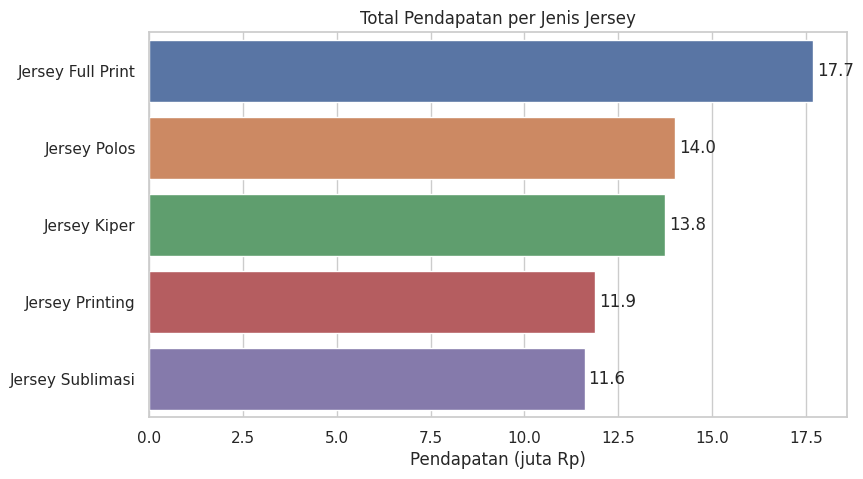

In [5]:
rev = df.groupby('Jenis_Jersey')['Total_Penjualan'].sum().sort_values(ascending=False)
ax = sns.barplot(x=rev.values/1e6, y=rev.index, hue=rev.index, legend=False, orient='h')
ax.set_title('Total Pendapatan per Jenis Jersey')
ax.set_xlabel('Pendapatan (juta Rp)'); ax.set_ylabel('')
for i,v in enumerate(rev.values/1e6): ax.text(v+0.1, i, f'{v:.1f}', va='center')
plt.show()

**Interpretasi:** Jersey Full Print menghasilkan pendapatan tertinggi (Rp 17,7 juta) berkat harga satuan paling mahal, meski jumlah terjualnya bukan yang terbanyak.

### 3.2 Jumlah Unit Terjual per Jenis Jersey

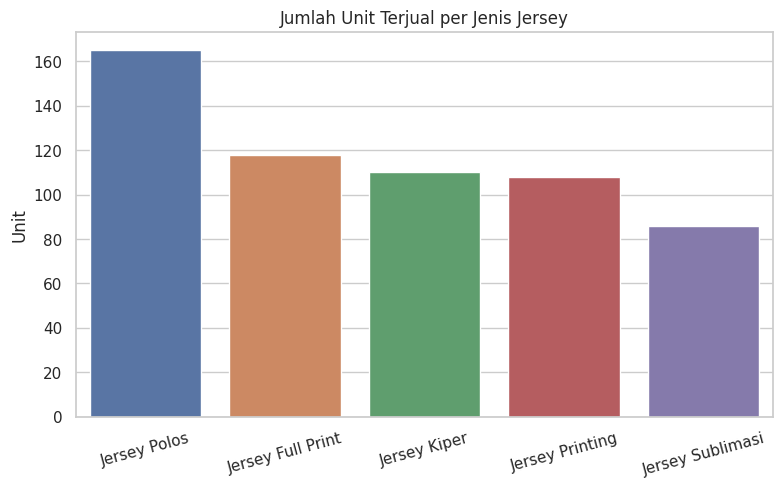

In [6]:
qty = df.groupby('Jenis_Jersey')['Jumlah_Terjual'].sum().sort_values(ascending=False)
ax = sns.barplot(x=qty.index, y=qty.values, hue=qty.index, legend=False)
ax.set_title('Jumlah Unit Terjual per Jenis Jersey'); ax.set_xlabel(''); ax.set_ylabel('Unit')
plt.xticks(rotation=15); plt.show()

**Interpretasi:** Jersey Polos paling banyak terjual (165 unit) karena harganya paling terjangkau, tetapi kontribusi pendapatannya hanya peringkat kedua. Volume tinggi belum tentu berarti pendapatan tertinggi.

### 3.3 Proporsi Kontribusi Pendapatan (Donut Chart)

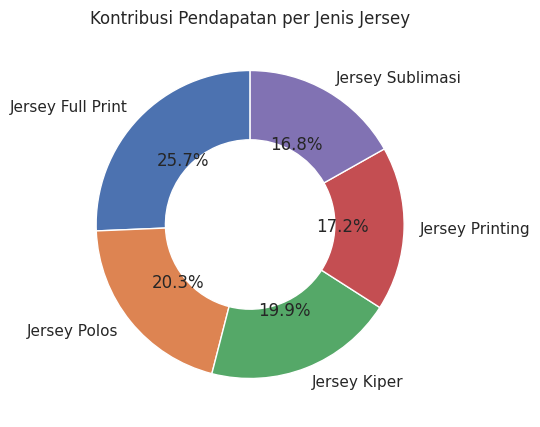

In [7]:
plt.pie(rev.values, labels=rev.index, autopct='%1.1f%%', startangle=90, wedgeprops=dict(width=0.45))
plt.title('Kontribusi Pendapatan per Jenis Jersey'); plt.show()

**Interpretasi:** Kontribusi pendapatan relatif merata di lima jenis jersey. Tidak ada satu produk yang mendominasi, sehingga risiko ketergantungan pada satu produk rendah.

### 3.4 Tren Pendapatan Mingguan (Line Chart)

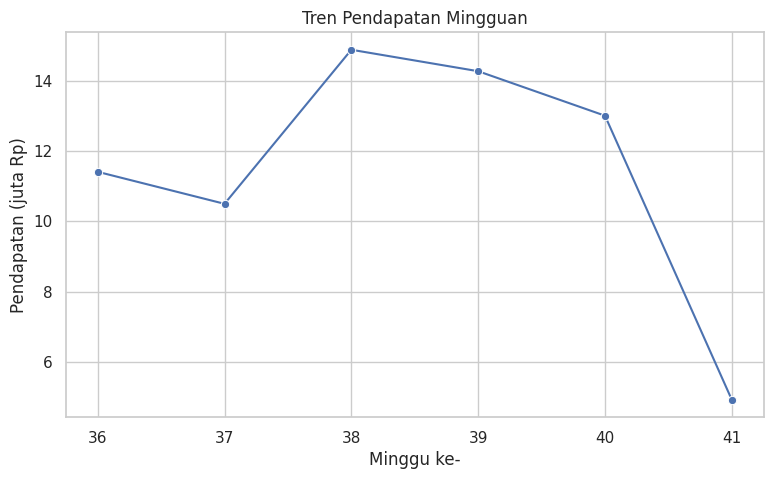

In [8]:
wk = df.groupby('Minggu_Ke')['Total_Penjualan'].sum()
ax = sns.lineplot(x=wk.index.astype(str), y=wk.values/1e6, marker='o')
ax.set_title('Tren Pendapatan Mingguan'); ax.set_xlabel('Minggu ke-'); ax.set_ylabel('Pendapatan (juta Rp)')
plt.show()

**Interpretasi:** Pendapatan naik tajam di minggu ke-38 dan bertahan tinggi sampai minggu ke-40. Minggu ke-41 terlihat rendah karena datanya hanya mencakup 6-7 Oktober (minggu belum lengkap), bukan karena penjualan benar-benar turun.

### 3.5 Pendapatan per Hari dalam Seminggu

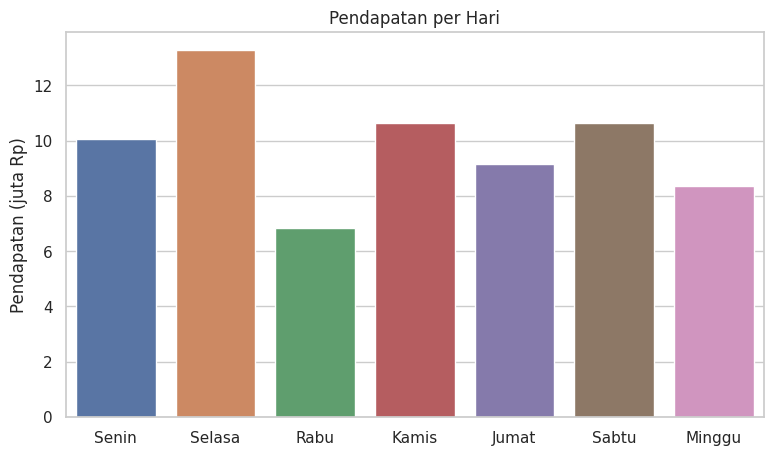

In [9]:
urut = ['Senin','Selasa','Rabu','Kamis','Jumat','Sabtu','Minggu']
hr = df.groupby('Hari')['Total_Penjualan'].sum().reindex(urut)
ax = sns.barplot(x=hr.index, y=hr.values/1e6, hue=hr.index, legend=False)
ax.set_title('Pendapatan per Hari'); ax.set_xlabel(''); ax.set_ylabel('Pendapatan (juta Rp)')
plt.show()

**Interpretasi:** Selasa menjadi hari dengan pendapatan tertinggi, sedangkan Rabu terendah. Pola ini bisa dipakai untuk menentukan hari promosi.

### 3.6 Distribusi Jumlah Terjual per Jenis (Boxplot)

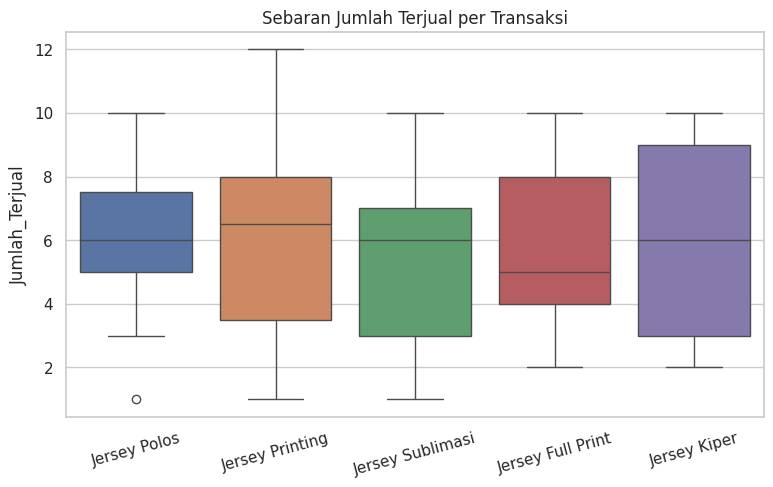

In [10]:
ax = sns.boxplot(data=df, x='Jenis_Jersey', y='Jumlah_Terjual', hue='Jenis_Jersey', legend=False)
ax.set_title('Sebaran Jumlah Terjual per Transaksi'); ax.set_xlabel('')
plt.xticks(rotation=15); plt.show()

**Interpretasi:** Boxplot menunjukkan seberapa bervariasi ukuran pesanan tiap jenis jersey. Rentang yang lebar berarti pesanan bervariasi dari kecil (perorangan) sampai besar (satu tim).

### 3.7 Distribusi Ukuran Jersey

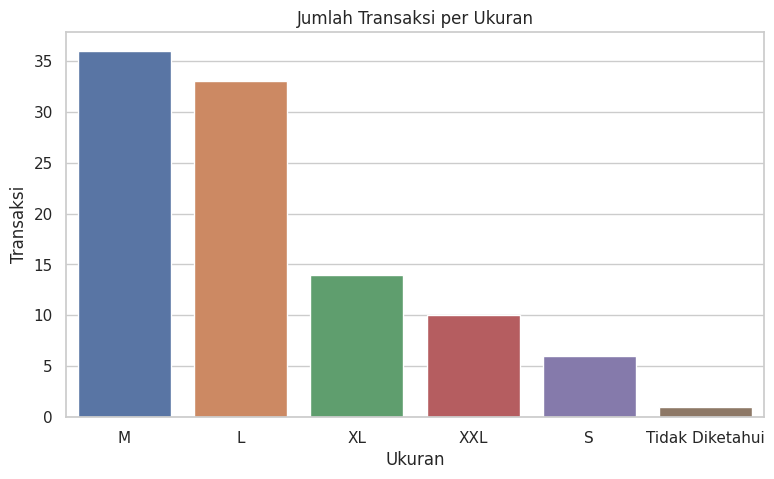

In [11]:
uk = df['Ukuran_Jersey'].value_counts()
ax = sns.barplot(x=uk.index, y=uk.values, hue=uk.index, legend=False)
ax.set_title('Jumlah Transaksi per Ukuran'); ax.set_xlabel('Ukuran'); ax.set_ylabel('Transaksi')
plt.show()

**Interpretasi:** Ukuran M dan L paling diminati dan mendominasi transaksi, sedangkan S paling jarang. Stok sebaiknya difokuskan pada M dan L.

### 3.8 Heatmap Jenis Jersey x Ukuran (Unit Terjual)

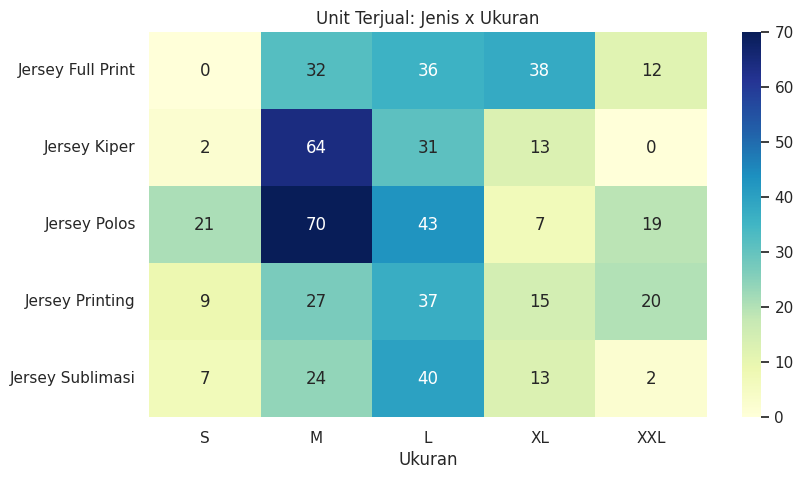

In [12]:
pt = df[df['Ukuran_Jersey']!='Tidak Diketahui'].pivot_table(index='Jenis_Jersey', columns='Ukuran_Jersey',
        values='Jumlah_Terjual', aggfunc='sum', fill_value=0)[['S','M','L','XL','XXL']]
ax = sns.heatmap(pt, annot=True, fmt='d', cmap='YlGnBu')
ax.set_title('Unit Terjual: Jenis x Ukuran'); ax.set_xlabel('Ukuran'); ax.set_ylabel('')
plt.show()

**Interpretasi:** Heatmap membantu melihat kombinasi jenis dan ukuran yang paling laku (warna paling gelap) untuk perencanaan stok.

## 4. Kesimpulan
1. **Full Print** menyumbang pendapatan terbesar, **Polos** terlaris dari sisi jumlah unit.
2. Pendapatan **mulai naik di minggu ke-38** dan bertahan tinggi sampai minggu ke-40.
3. **Selasa** adalah hari tersibuk, **Rabu** paling sepi.
4. Ukuran **M dan L** paling diminati.

**Saran:** prioritaskan stok ukuran M/L, dorong promosi Full Print karena margin per unit tinggi, dan beri promo di hari sepi.

*Catatan: dataset ini terdiri dari data enrichment, sebagian baris dibuat sebagai simulasi lanjutan.*